# Huấn luyện U-Net tự cài đặt trên Kvasir-SEG

Notebook này dùng:
- Kiến trúc U-Net trong `unet.py` bạn đã gửi: 4 mức encoder, bottleneck, decoder với skip connection.
- Manifest `kvasir_seg_manifest.csv` (hoặc `kvasir-seg.csv`) để xác định cặp ảnh–mask.
- Ảnh Kvasir-SEG đã được thêm vào Kaggle Input.

**Lưu ý:** CSV là bảng chỉ mục, không chứa dữ liệu ảnh. Trên Kaggle cần Add Input cả (1) bộ ảnh Kvasir-SEG và (2) file CSV manifest.

## 1. Cấu hình và kiểm tra thiết bị

Mặc định giữ `base_channels=64` đúng với U-Net ban đầu. Nếu GPU hết bộ nhớ, trước tiên giảm `BATCH_SIZE` từ 2 xuống 1; không tự ý đổi kiến trúc khi chưa ghi nhận thay đổi thí nghiệm.

In [1]:
from pathlib import Path
import os
import random
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 2
EPOCHS = 50
LEARNING_RATE = 1e-4
NUM_WORKERS = 2
BASE_CHANNELS = 64
INPUT_ROOT = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working/unet_kvasir")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | PyTorch: {torch.__version__}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU chưa bật. Kaggle > Settings > Accelerator > GPU.")

Device: cuda | PyTorch: 2.11.0+cu130
GPU: Tesla T4


## 2. Tìm và đọc manifest CSV

Notebook tự tìm một trong các tên `kvasir_seg_manifest.csv`, `kvasir-seg.csv` hoặc `kvasir_seg.csv` trong `/kaggle/input`. Nếu có nhiều file trùng tên hợp lệ, notebook dừng để tránh chọn nhầm.

In [2]:
MANIFEST_NAMES = {
    "kvasir_seg_manifest.csv",
    "kvasir-seg.csv",
    "kvasir_seg.csv",
}

manifest_candidates = sorted(
    p for p in INPUT_ROOT.rglob("*.csv")
    if p.name.lower() in MANIFEST_NAMES
)

if not manifest_candidates:
    raise FileNotFoundError(
        "Không tìm thấy CSV manifest trong /kaggle/input. "
        "Hãy Add Input file kvasir_seg_manifest.csv lên Kaggle."
    )

if len(manifest_candidates) > 1:
    print("Tìm thấy nhiều CSV:")
    for p in manifest_candidates:
        print(" -", p)
    raise RuntimeError(
        "Có nhiều manifest. Hãy giữ một file hoặc chỉ định MANIFEST_PATH thủ công."
    )

MANIFEST_PATH = manifest_candidates[0]
df = pd.read_csv(MANIFEST_PATH)

required_columns = {"name", "raw_image", "raw_mask"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"CSV thiếu các cột bắt buộc: {sorted(missing_columns)}")

if df[list(required_columns)].isna().any().any():
    raise ValueError("CSV có giá trị rỗng trong name/raw_image/raw_mask.")

if df["name"].duplicated().any():
    raise ValueError("Cột name có ID trùng lặp.")

print("Manifest:", MANIFEST_PATH)
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())

Manifest: /kaggle/input/datasets/namphmbuwu/kvasir-seg/kvasir_seg_manifest.csv
Rows: 1000
Columns: ['name', 'raw_image', 'raw_mask', 'orig_height', 'orig_width', 'fg_ratio_orig', 'fg_ratio_256', 'n_components', 'sha256_image', 'sha256_mask']


,name,raw_image,raw_mask,orig_height,orig_width,fg_ratio_orig,fg_ratio_256,n_components,sha256_image,sha256_mask
0,cju0qkwl35piu0993l0dewei2,data/raw/kvasir_seg/Kvasir-SEG/images/cju0qkwl...,data/raw/kvasir_seg/Kvasir-SEG/masks/cju0qkwl3...,529,622,0.282773,0.282822,1,71179abc4b011cc99bddb3344e3e114765b32bdf77e788...,11debb8496025566e43cda40a55720422b487d5f7892ff...
1,cju0qoxqj9q6s0835b43399p4,data/raw/kvasir_seg/Kvasir-SEG/images/cju0qoxq...,data/raw/kvasir_seg/Kvasir-SEG/masks/cju0qoxqj...,1070,1348,0.270595,0.270584,1,a2fbe43d8b079bcf3290f1daea4af382500eb2505289a7...,7f8035336e3e2dcc4445c560007c72999991d02e557d1f...
2,cju0qx73cjw570799j4n5cjze,data/raw/kvasir_seg/Kvasir-SEG/images/cju0qx73...,data/raw/kvasir_seg/Kvasir-SEG/masks/cju0qx73c...,529,619,0.318826,0.318756,1,abb709c70585be9c57dfbd98d59c06f4c2d0f7b6b81730...,cfe824e77a212c45ba839415b46c2b97707474e093565a...
3,cju0roawvklrq0799vmjorwfv,data/raw/kvasir_seg/Kvasir-SEG/images/cju0roaw...,data/raw/kvasir_seg/Kvasir-SEG/masks/cju0roawv...,528,622,0.108497,0.108749,3,6b3e0177e6c24d692456c9e1125e3d53f73c8372834a20...,f870a49fc6311e1c660a7647be892c5f206d5e15fefd74...
4,cju0rx1idathl0835detmsp84,data/raw/kvasir_seg/Kvasir-SEG/images/cju0rx1i...,data/raw/kvasir_seg/Kvasir-SEG/masks/cju0rx1id...,528,617,0.072768,0.072937,1,b004545e40c76da16ec2932905186353c05cb170295cef...,3d9769f509ec7f72a0bb4ed5d12242f07d7f5c2e8c7b84...


## 3. Ghép đường dẫn trong CSV với file ảnh thực tế

Trong manifest, `raw_image` và `raw_mask` là đường dẫn tương đối từ máy tạo manifest. Kaggle có thể mount dữ liệu ở một vị trí khác, vì vậy notebook tìm file theo tên file bên trong `/kaggle/input`, đồng thời kiểm tra thư mục `images` hoặc `masks`.

In [3]:

from pathlib import Path

# Dataset locations
DATASET_ROOTS = [
    Path("/kaggle/input/datasets/namphmbuwu/kvasir-seg"),
    Path("/kaggle/input/datasets/bhavnagowda010/kvasir-seg-3"),
]

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def build_index(root, folder_names):
    index = {}

    for p in root.rglob("*"):
        if (
            p.is_file()
            and p.suffix.lower() in EXTENSIONS
            and p.parent.name.lower() in folder_names
        ):
            key = p.stem.lower()

            if key in index:
                raise ValueError(f"Duplicate file: {key}")

            index[key] = p

    return index


# Manifest keys
image_keys = df["raw_image"].map(
    lambda x: Path(str(x)).stem.lower()
)
mask_keys = df["raw_mask"].map(
    lambda x: Path(str(x)).stem.lower()
)

if not image_keys.equals(mask_keys):
    raise ValueError("Image-mask IDs do not match in manifest.")

expected = set(image_keys)

# Find the first complete dataset
selected = None

for root in DATASET_ROOTS:
    if not root.exists():
        print(f"Not found: {root}")
        continue

    images = build_index(root, {"images", "image"})
    masks = build_index(root, {"masks", "mask"})

    missing_images = expected - images.keys()
    missing_masks = expected - masks.keys()

    print(
        f"{root.name}: "
        f"images={len(images)}, masks={len(masks)}, "
        f"missing={len(missing_images) + len(missing_masks)}"
    )

    if not missing_images and not missing_masks:
        selected = (root, images, masks)
        break

if selected is None:
    raise FileNotFoundError(
        "Không tìm thấy dataset chứa đầy đủ 1000 ảnh và 1000 mask."
    )

DATASET_ROOT, images, masks = selected

# Build image-mask pairs
df["image_path"] = image_keys.map(images)
df["mask_path"] = mask_keys.map(masks)

pairs = list(zip(df["image_path"], df["mask_path"]))

assert len(pairs) == len(df)
assert all(i.stem.lower() == m.stem.lower() for i, m in pairs)

print("\n========== DATASET READY ==========")
print("Selected:", DATASET_ROOT)
print("Images:", len(images))
print("Masks:", len(masks))
print("Valid pairs:", len(pairs))
print("Status: PASSED")
print("Example:", pairs[0])


kvasir-seg: images=0, masks=0, missing=2000
kvasir-seg-3: images=1000, masks=1000, missing=0

========== DATASET READY ==========
Selected: /kaggle/input/datasets/bhavnagowda010/kvasir-seg-3
Images: 1000
Masks: 1000
Valid pairs: 1000
Status: PASSED
Example: (PosixPath('/kaggle/input/datasets/bhavnagowda010/kvasir-seg-3/Kvasir-SEG/images/cju0qkwl35piu0993l0dewei2.jpg'), PosixPath('/kaggle/input/datasets/bhavnagowda010/kvasir-seg-3/Kvasir-SEG/masks/cju0qkwl35piu0993l0dewei2.jpg'))


## 4. Chia Train / Validation / Test

Chia theo tỷ lệ 80% / 10% / 10%, cố định `seed=42`. Tập test được giữ riêng, không dùng để chọn epoch hoặc điều chỉnh mô hình.

In [4]:
train_df, temp_df = train_test_split(
    df, test_size=0.20, random_state=SEED, shuffle=True
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, shuffle=True
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train      : {len(train_df)}")
print(f"Validation : {len(val_df)}")
print(f"Test       : {len(test_df)}")

Train      : 800
Validation : 100
Test       : 100


## 5. Dataset và DataLoader

Ảnh được resize bằng bilinear, mask bằng nearest-neighbor. Ảnh RGB được đưa về `[0, 1]`; mask được chuyển thành nhị phân bằng ngưỡng 128.

In [5]:
RESAMPLING = Image.Resampling if hasattr(Image, "Resampling") else Image

class KvasirSegDataset(Dataset):
    def __init__(self, frame, image_size=IMAGE_SIZE):
        self.frame = frame.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB").resize(
                (self.image_size, self.image_size),
                RESAMPLING.BILINEAR
            )

        with Image.open(row["mask_path"]) as msk:
            mask = msk.convert("L").resize(
                (self.image_size, self.image_size),
                RESAMPLING.NEAREST
            )

        image = np.asarray(image, dtype=np.float32) / 255.0
        mask = np.asarray(mask, dtype=np.uint8)
        mask = (mask >= 128).astype(np.float32)

        image = torch.from_numpy(image).permute(2, 0, 1).contiguous()
        mask = torch.from_numpy(mask[None, ...]).contiguous()

        return image, mask, str(row["name"])

train_dataset = KvasirSegDataset(train_df)
val_dataset = KvasirSegDataset(val_df)
test_dataset = KvasirSegDataset(test_df)

loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": device.type == "cuda",
    "persistent_workers": NUM_WORKERS > 0,
}

train_loader = DataLoader(
    train_dataset, shuffle=True, **loader_options
)
val_loader = DataLoader(
    val_dataset, shuffle=False, **loader_options
)
test_loader = DataLoader(
    test_dataset, shuffle=False, **loader_options
)

images, masks, names = next(iter(train_loader))
print("Image batch:", tuple(images.shape))
print("Mask batch :", tuple(masks.shape))
print("Mask values:", torch.unique(masks))

Image batch: (2, 3, 256, 256)
Mask batch : (2, 1, 256, 256)
Mask values: tensor([0., 1.])


## 6. Kiến trúc U-Net gốc

Giữ nguyên thiết kế trong `unet.py` bạn gửi: hai Conv 3×3 + ReLU ở mỗi khối, bốn lần MaxPool, bottleneck, ConvTranspose2d và skip connection. `forward()` trả logits, không sigmoid.

In [6]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class UpBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(
            in_channels, out_channels, kernel_size=2, stride=2
        )
        self.conv = DoubleConv(out_channels * 2, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        dh = skip.shape[-2] - x.shape[-2]
        dw = skip.shape[-1] - x.shape[-1]
        x = F.pad(
            x,
            [dw // 2, dw - dw // 2, dh // 2, dh - dh // 2]
        )
        return self.conv(torch.cat([skip, x], dim=1))


class UNet(nn.Module):
    def __init__(
        self,
        in_channels=3,
        out_channels=1,
        base_channels=64
    ):
        super().__init__()

        if min(in_channels, out_channels, base_channels) < 1:
            raise ValueError("Số kênh phải là số nguyên dương.")

        c = base_channels
        self.in_channels = in_channels
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.enc1 = DoubleConv(in_channels, c)
        self.enc2 = DoubleConv(c, c * 2)
        self.enc3 = DoubleConv(c * 2, c * 4)
        self.enc4 = DoubleConv(c * 4, c * 8)

        self.bottleneck = DoubleConv(c * 8, c * 16)

        self.dec4 = UpBlock(c * 16, c * 8)
        self.dec3 = UpBlock(c * 8, c * 4)
        self.dec2 = UpBlock(c * 4, c * 2)
        self.dec1 = UpBlock(c * 2, c)

        self.head = nn.Conv2d(c, out_channels, kernel_size=1)

    def forward(self, x):
        if x.ndim != 4 or x.shape[1] != self.in_channels:
            raise ValueError(
                f"Input phải có dạng (B, {self.in_channels}, H, W)"
            )
        if min(x.shape[-2:]) < 16:
            raise ValueError("H và W phải >= 16.")

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        x = self.bottleneck(self.pool(e4))
        x = self.dec4(x, e4)
        x = self.dec3(x, e3)
        x = self.dec2(x, e2)
        x = self.dec1(x, e1)

        return self.head(x)


model = UNet(
    in_channels=3,
    out_channels=1,
    base_channels=BASE_CHANNELS
).to(device)

num_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {num_parameters:,}")

with torch.no_grad():
    sample_logits = model(images[:1].to(device))
print("Output shape:", tuple(sample_logits.shape))

Trainable parameters: 31,031,745
Output shape: (1, 1, 256, 256)


## 7. Loss, optimizer và metrics

Loss kết hợp BCE và soft Dice với trọng số 0.5 / 0.5. Dice và IoU báo cáo theo tổng pixel của toàn bộ tập, dùng threshold 0.5.

In [7]:
class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, dice_weight=0.5, eps=1e-7):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight
        self.eps = eps

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)

        probs = torch.sigmoid(logits)
        dims = (1, 2, 3)
        intersection = (probs * targets).sum(dim=dims)
        denominator = probs.sum(dim=dims) + targets.sum(dim=dims)
        dice = (2 * intersection + self.eps) / (denominator + self.eps)
        dice_loss = 1 - dice.mean()

        return (
            self.bce_weight * bce_loss
            + self.dice_weight * dice_loss
        )


criterion = BCEDiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=4
)

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_samples = 0
    intersection_total = 0.0
    prediction_total = 0.0
    target_total = 0.0

    for images, masks, _ in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, masks)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        predictions = (torch.sigmoid(logits) >= 0.5).float()
        intersection_total += (predictions * masks).sum().item()
        prediction_total += predictions.sum().item()
        target_total += masks.sum().item()

    eps = 1e-7
    dice = (2 * intersection_total + eps) / (
        prediction_total + target_total + eps
    )
    iou = (intersection_total + eps) / (
        prediction_total + target_total - intersection_total + eps
    )

    return {
        "loss": total_loss / max(total_samples, 1),
        "dice": dice,
        "iou": iou,
    }

## 8. Huấn luyện và lưu checkpoint tốt nhất

Checkpoint được chọn theo Validation Dice. Early stopping dừng nếu Validation Dice không cải thiện trong 10 epoch liên tiếp.

In [8]:
BEST_MODEL_PATH = OUTPUT_DIR / "best_unet_kvasir.pt"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"
EARLY_STOPPING_PATIENCE = 10

history = []
best_val_dice = -1.0
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    train_metrics = run_epoch(model, train_loader, optimizer)
    val_metrics = run_epoch(model, val_loader)

    scheduler.step(val_metrics["dice"])
    current_lr = optimizer.param_groups[0]["lr"]

    row = {
        "epoch": epoch,
        "lr": current_lr,
        "train_loss": train_metrics["loss"],
        "train_dice": train_metrics["dice"],
        "train_iou": train_metrics["iou"],
        "val_loss": val_metrics["loss"],
        "val_dice": val_metrics["dice"],
        "val_iou": val_metrics["iou"],
    }
    history.append(row)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    improved = val_metrics["dice"] > best_val_dice
    if improved:
        best_val_dice = val_metrics["dice"]
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_dice": best_val_dice,
                "config": {
                    "image_size": IMAGE_SIZE,
                    "base_channels": BASE_CHANNELS,
                    "batch_size": BATCH_SIZE,
                    "learning_rate": LEARNING_RATE,
                    "seed": SEED,
                },
            },
            BEST_MODEL_PATH,
        )
    else:
        epochs_without_improvement += 1

    elapsed = time.time() - start_time
    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"Train Loss {train_metrics['loss']:.4f} | "
        f"Train Dice {train_metrics['dice']:.4f} | "
        f"Val Loss {val_metrics['loss']:.4f} | "
        f"Val Dice {val_metrics['dice']:.4f} | "
        f"Val IoU {val_metrics['iou']:.4f} | "
        f"LR {current_lr:.2e} | {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping: validation Dice không cải thiện.")
        break

print("\nBest validation Dice:", round(best_val_dice, 4))
print("Best checkpoint:", BEST_MODEL_PATH)

Epoch 001/50 | Train Loss 0.5855 | Train Dice 0.1865 | Val Loss 0.5657 | Val Dice 0.3478 | Val IoU 0.2105 | LR 1.00e-04 | 79.7s | BEST
Epoch 002/50 | Train Loss 0.5513 | Train Dice 0.3742 | Val Loss 0.5643 | Val Dice 0.3821 | Val IoU 0.2362 | LR 1.00e-04 | 82.7s | BEST
Epoch 003/50 | Train Loss 0.5507 | Train Dice 0.3865 | Val Loss 0.5622 | Val Dice 0.3476 | Val IoU 0.2104 | LR 1.00e-04 | 82.9s
Epoch 004/50 | Train Loss 0.5453 | Train Dice 0.3903 | Val Loss 0.5570 | Val Dice 0.3811 | Val IoU 0.2354 | LR 1.00e-04 | 82.7s
Epoch 005/50 | Train Loss 0.5277 | Train Dice 0.4337 | Val Loss 0.5177 | Val Dice 0.4605 | Val IoU 0.2991 | LR 1.00e-04 | 83.3s | BEST
Epoch 006/50 | Train Loss 0.4951 | Train Dice 0.4818 | Val Loss 0.5055 | Val Dice 0.4388 | Val IoU 0.2811 | LR 1.00e-04 | 82.6s
Epoch 007/50 | Train Loss 0.4910 | Train Dice 0.4885 | Val Loss 0.5081 | Val Dice 0.4260 | Val IoU 0.2707 | LR 1.00e-04 | 82.6s
Epoch 008/50 | Train Loss 0.4856 | Train Dice 0.4898 | Val Loss 0.4981 | Val Dice 0

## 9. Đánh giá trên Test

Nạp checkpoint có Validation Dice tốt nhất và đánh giá trên test. Không dùng test để chọn checkpoint.

In [9]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])

test_metrics = run_epoch(model, test_loader)

results = {
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_dice": float(checkpoint["best_val_dice"]),
    "test_loss": float(test_metrics["loss"]),
    "test_dice": float(test_metrics["dice"]),
    "test_iou": float(test_metrics["iou"]),
    "test_samples": int(len(test_dataset)),
}

with open(OUTPUT_DIR / "test_metrics.json", "w") as f:
    json.dump(results, f, indent=2)

print("========== TEST RESULTS ==========")
for key, value in results.items():
    print(f"{key}: {value}")

========== TEST RESULTS ==========
best_epoch: 32
best_validation_dice: 0.7633562020619311
test_loss: 0.2686294662952423
test_dice: 0.7679535535358721
test_iou: 0.6233154243006455
test_samples: 100


## 10. Biểu đồ quá trình huấn luyện

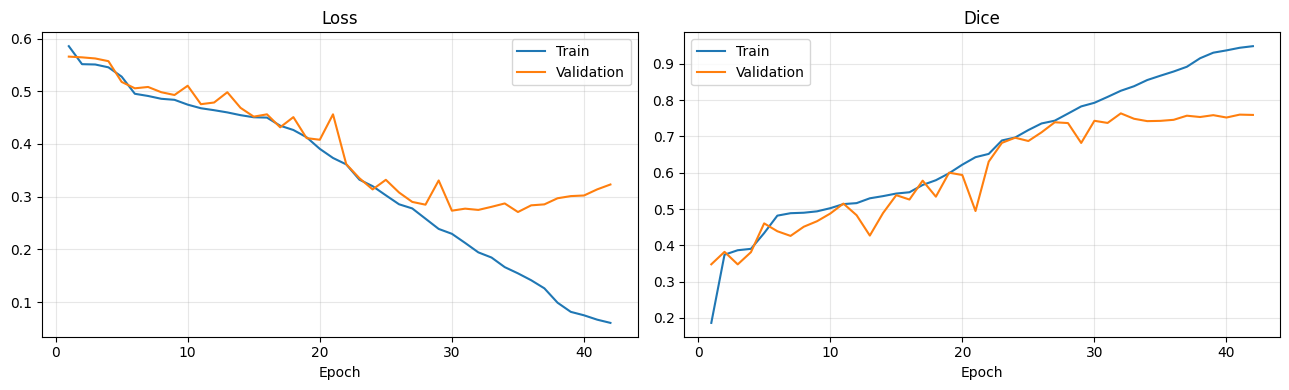

In [10]:
history_df = pd.read_csv(HISTORY_PATH)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_df["epoch"], history_df["train_dice"], label="Train")
axes[1].plot(history_df["epoch"], history_df["val_dice"], label="Validation")
axes[1].set_title("Dice")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150)
plt.show()

## 11. Hiển thị dự đoán trên Test

Mỗi hàng gồm ảnh nội soi, Ground Truth và Prediction. Prediction được tạo bằng sigmoid rồi threshold 0.5.

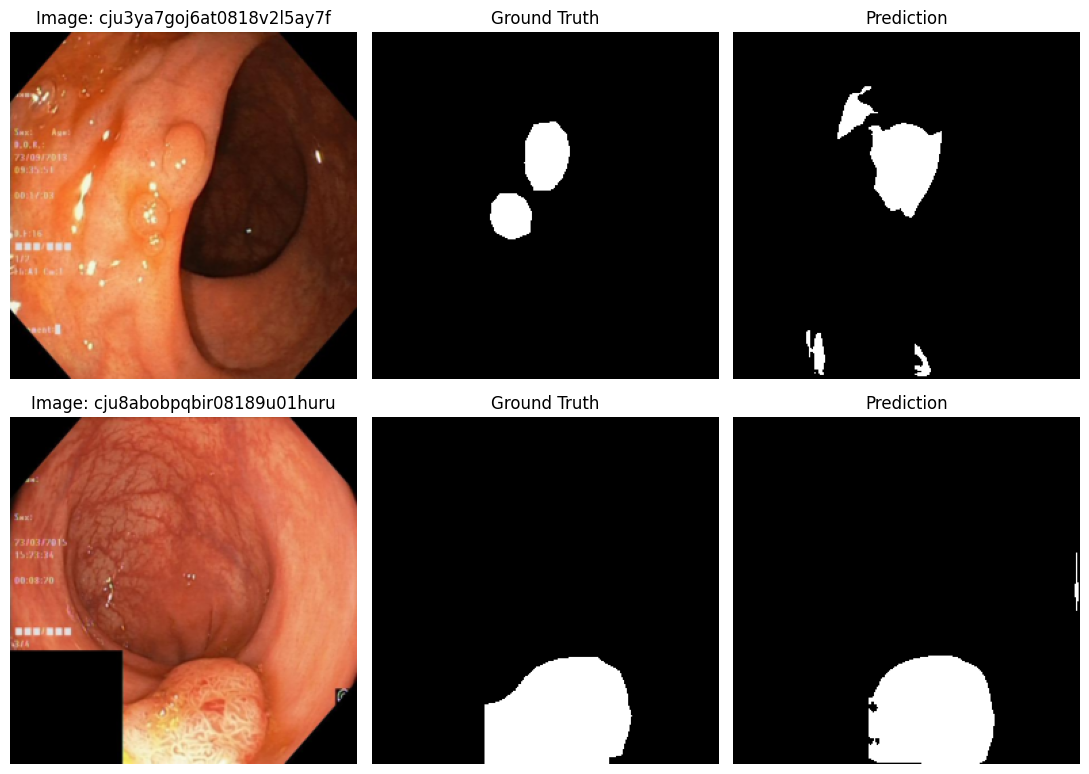

In [11]:
@torch.no_grad()
def show_predictions(loader, n=5):
    model.eval()
    images, masks, names = next(iter(loader))
    logits = model(images[:n].to(device))
    predictions = (torch.sigmoid(logits) >= 0.5).float().cpu()

    count = min(n, len(images))
    fig, axes = plt.subplots(count, 3, figsize=(11, 4 * count))
    if count == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(count):
        image = images[i].permute(1, 2, 0).numpy()
        mask = masks[i, 0].numpy()
        pred = predictions[i, 0].numpy()

        axes[i, 0].imshow(image)
        axes[i, 0].set_title(f"Image: {names[i]}")
        axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title("Ground Truth")
        axes[i, 2].imshow(pred, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title("Prediction")

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

show_predictions(test_loader, n=5)

## 12. Tính kết quả riêng cho từng ảnh test

In [12]:
checkpoint_analysis = torch.load(
    BEST_MODEL_PATH, map_location="cpu", weights_only=True
)
model.load_state_dict(checkpoint_analysis["model_state_dict"])
model.to(device).eval()

THRESHOLD = 0.5
analysis_rows = []
analysis_cache = {}

with torch.inference_mode():
    for images_batch, masks_batch, names_batch in test_loader:
        probabilities = model(images_batch.to(device)).sigmoid()
        predictions = probabilities.ge(THRESHOLD).cpu().numpy()[:, 0]
        targets = masks_batch.numpy()[:, 0] >= 0.5

        for i, name in enumerate(names_batch):
            name = str(name)
            gt = targets[i]
            pred = predictions[i]

            tp = int(np.count_nonzero(pred & gt))
            fp = int(np.count_nonzero(pred & ~gt))
            fn = int(np.count_nonzero(~pred & gt))
            tn = int(np.count_nonzero(~pred & ~gt))

            gt_pixels = tp + fn
            pred_pixels = tp + fp
            dice_denominator = 2 * tp + fp + fn
            union = tp + fp + fn

            analysis_rows.append({
                "name": name,
                "dice": (
                    2 * tp / dice_denominator
                    if dice_denominator else 1.0
                ),
                "iou": tp / union if union else 1.0,
                "precision": tp / pred_pixels if pred_pixels else np.nan,
                "recall": tp / gt_pixels if gt_pixels else np.nan,
                "tp": tp,
                "fp": fp,
                "fn": fn,
                "tn": tn,
                "gt_pixels": gt_pixels,
                "pred_pixels": pred_pixels,
                "gt_ratio": gt_pixels / gt.size,
                "touches_border": bool(
                    gt[0].any() or gt[-1].any()
                    or gt[:, 0].any() or gt[:, -1].any()
                ),
            })

            # Lưu ảnh và mask để vẽ lại mà không cần suy luận thêm.
            analysis_cache[name] = {
                "image": images_batch[i].permute(1, 2, 0).numpy().copy(),
                "gt": gt.copy(),
                "pred": pred.copy(),
            }

analysis_df = pd.DataFrame(analysis_rows)

assert len(analysis_df) == len(test_dataset), "Chưa đánh giá đủ ảnh test"
assert analysis_df["name"].is_unique, "Tên ảnh test bị trùng"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
analysis_df.to_csv(OUTPUT_DIR / "test_per_image.csv", index=False)

# Tính lại metric gộp để đối chiếu với kết quả notebook hiện tại.
tp_total = int(analysis_df["tp"].sum())
fp_total = int(analysis_df["fp"].sum())
fn_total = int(analysis_df["fn"].sum())

global_denominator = 2 * tp_total + fp_total + fn_total
global_union = tp_total + fp_total + fn_total

analysis_summary = {
    "checkpoint_epoch": int(checkpoint_analysis["epoch"]),
    "threshold": THRESHOLD,
    "test_images": len(analysis_df),
    "global_dice": (
        2 * tp_total / global_denominator
        if global_denominator else 1.0
    ),
    "global_iou": (
        tp_total / global_union if global_union else 1.0
    ),
    "mean_image_dice": float(analysis_df["dice"].mean()),
    "mean_image_iou": float(analysis_df["iou"].mean()),
    "median_image_dice": float(analysis_df["dice"].median()),
}

with open(OUTPUT_DIR / "test_analysis_summary.json", "w") as f:
    json.dump(analysis_summary, f, indent=2)

print(json.dumps(analysis_summary, indent=2))
display(analysis_df.head())

{
  "checkpoint_epoch": 32,
  "threshold": 0.5,
  "test_images": 100,
  "global_dice": 0.767953553535861,
  "global_iou": 0.623315424300616,
  "mean_image_dice": 0.7635773831274395,
  "mean_image_iou": 0.6580304302824213,
  "median_image_dice": 0.8287750323350423
}


,name,dice,iou,precision,recall,tp,fp,fn,tn,gt_pixels,pred_pixels,gt_ratio,touches_border
0,cju3ya7goj6at0818v2l5ay7f,0.478893,0.314832,0.391130,0.617435,1367,2128,847,61194,2214,3495,0.033783,False
1,cju8abobpqbir08189u01huru,0.908057,0.831597,0.948034,0.871315,6148,337,908,58143,7056,6485,0.107666,True
2,cju32zhbnc1oy0801iyv1ix6p,0.613362,0.442337,0.531472,0.725085,11990,10570,4546,38430,16536,22560,0.252319,False
3,cju1brhsj3rls0855a1vgdlen,0.698972,0.537246,0.537467,0.999237,2618,2253,2,60663,2620,4871,0.039978,False
4,cju887ftknop008177nnjt46y,0.921092,0.853727,0.945278,0.898113,2142,124,243,63027,2385,2266,0.036392,False


## 13. So sánh theo diện tích polyp và vị trí chạm mép

Theo tỷ lệ diện tích mask thật:


,size_group,n,mean_dice,median_dice,mean_iou,mean_recall,mean_precision,precision_defined,recall_defined
0,1-<5%,19,0.6052,0.7369,0.5028,0.7286,0.6178,19,19
1,5-<20%,47,0.8323,0.8763,0.7351,0.8958,0.8002,47,47
2,>=20%,34,0.7571,0.8156,0.6383,0.6955,0.9028,34,34


Theo việc mask thật có chạm mép ảnh hay không:


,touches_border,n,mean_dice,median_dice,mean_iou,mean_recall,mean_precision,precision_defined,recall_defined
0,False,79,0.7773,0.8550,0.6781,0.8351,0.7758,79,79
1,True,21,0.7121,0.7721,0.5825,0.6487,0.8929,21,21


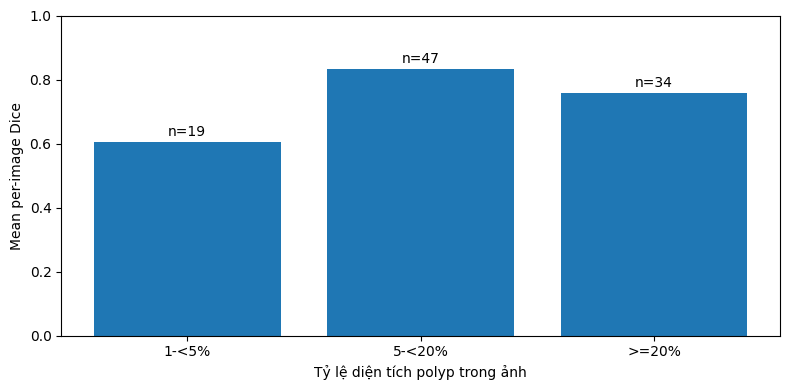

In [13]:
size_labels = ["<1%", "1-<5%", "5-<20%", ">=20%"]
size_categories = ["Empty"] + size_labels

analysis_df["size_group"] = pd.cut(
    analysis_df["gt_ratio"],
    bins=[0, 0.01, 0.05, 0.20, np.inf],
    labels=size_labels,
    right=False,
).astype(object)

analysis_df.loc[
    analysis_df["gt_pixels"] == 0, "size_group"
] = "Empty"

analysis_df["size_group"] = pd.Categorical(
    analysis_df["size_group"],
    categories=size_categories,
    ordered=True,
)

def summarize_groups(column):
    return (
        analysis_df.groupby(column, observed=True)
        .agg(
            n=("name", "size"),
            mean_dice=("dice", "mean"),
            median_dice=("dice", "median"),
            mean_iou=("iou", "mean"),
            mean_recall=("recall", "mean"),
            mean_precision=("precision", "mean"),
            precision_defined=("precision", "count"),
            recall_defined=("recall", "count"),
        )
        .reset_index()
    )

size_summary = summarize_groups("size_group")
border_summary = summarize_groups("touches_border")

size_summary.to_csv(
    OUTPUT_DIR / "test_by_size.csv", index=False
)
border_summary.to_csv(
    OUTPUT_DIR / "test_by_border.csv", index=False
)

print("Theo tỷ lệ diện tích mask thật:")
display(size_summary.round(4))

print("Theo việc mask thật có chạm mép ảnh hay không:")
display(border_summary.round(4))

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    size_summary["size_group"].astype(str),
    size_summary["mean_dice"],
)
ax.set_ylim(0, 1)
ax.set_xlabel("Tỷ lệ diện tích polyp trong ảnh")
ax.set_ylabel("Mean per-image Dice")

for i, row in size_summary.iterrows():
    ax.text(
        i,
        row["mean_dice"] + 0.02,
        f"n={int(row['n'])}",
        ha="center",
    )

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "dice_by_size.png", dpi=150)
plt.show()

# 14. Đếm các trường hợp đúng và các dạng lỗi

In [14]:
analysis_df["good_overlap"] = analysis_df["dice"] >= 0.8
analysis_df["poor_overlap"] = analysis_df["dice"] < 0.5

analysis_df["no_prediction"] = (
    (analysis_df["gt_pixels"] > 0)
    & (analysis_df["pred_pixels"] == 0)
)

analysis_df["no_overlap"] = (
    (analysis_df["gt_pixels"] > 0)
    & (analysis_df["tp"] == 0)
)

analysis_df["low_recall"] = (
    (analysis_df["gt_pixels"] > 0)
    & (analysis_df["recall"] < 0.5)
)

analysis_df["low_precision"] = (
    (analysis_df["pred_pixels"] > 0)
    & (analysis_df["precision"] < 0.5)
)

conditions = {
    "Dice >= 0.8": "good_overlap",
    "Dice < 0.5": "poor_overlap",
    "Có polyp nhưng không dự đoán vùng nào": "no_prediction",
    "Không có pixel dự đoán giao với polyp thật": "no_overlap",
    "Bỏ sót hơn 50% số pixel polyp": "low_recall",
    "Hơn 50% pixel dự đoán là nền theo GT": "low_precision",
}

frequency_df = pd.DataFrame([
    {
        "condition": label,
        "images": int(analysis_df[column].sum()),
        "percent_of_test": 100 * analysis_df[column].mean(),
    }
    for label, column in conditions.items()
])

frequency_df.to_csv(
    OUTPUT_DIR / "test_error_frequency.csv", index=False
)

# Cập nhật bảng từng ảnh với các nhóm và nhãn lỗi vừa thêm.
analysis_df.to_csv(
    OUTPUT_DIR / "test_per_image.csv", index=False
)

display(frequency_df.round(2))

print(
    "Các nhóm có thể chồng lấn; "
    "tỷ lệ đều tính trên toàn bộ tập test."
)

,condition,images,percent_of_test
0,Dice >= 0.8,59,59.0
1,Dice < 0.5,10,10.0
2,Có polyp nhưng không dự đoán vùng nào,0,0.0
3,Không có pixel dự đoán giao với polyp thật,2,2.0
4,Bỏ sót hơn 50% số pixel polyp,12,12.0
5,Hơn 50% pixel dự đoán là nền theo GT,7,7.0


Các nhóm có thể chồng lấn; tỷ lệ đều tính trên toàn bộ tập test.


## 15. Hiển thị 5 ảnh tốt nhất và 5 ảnh kém nhất

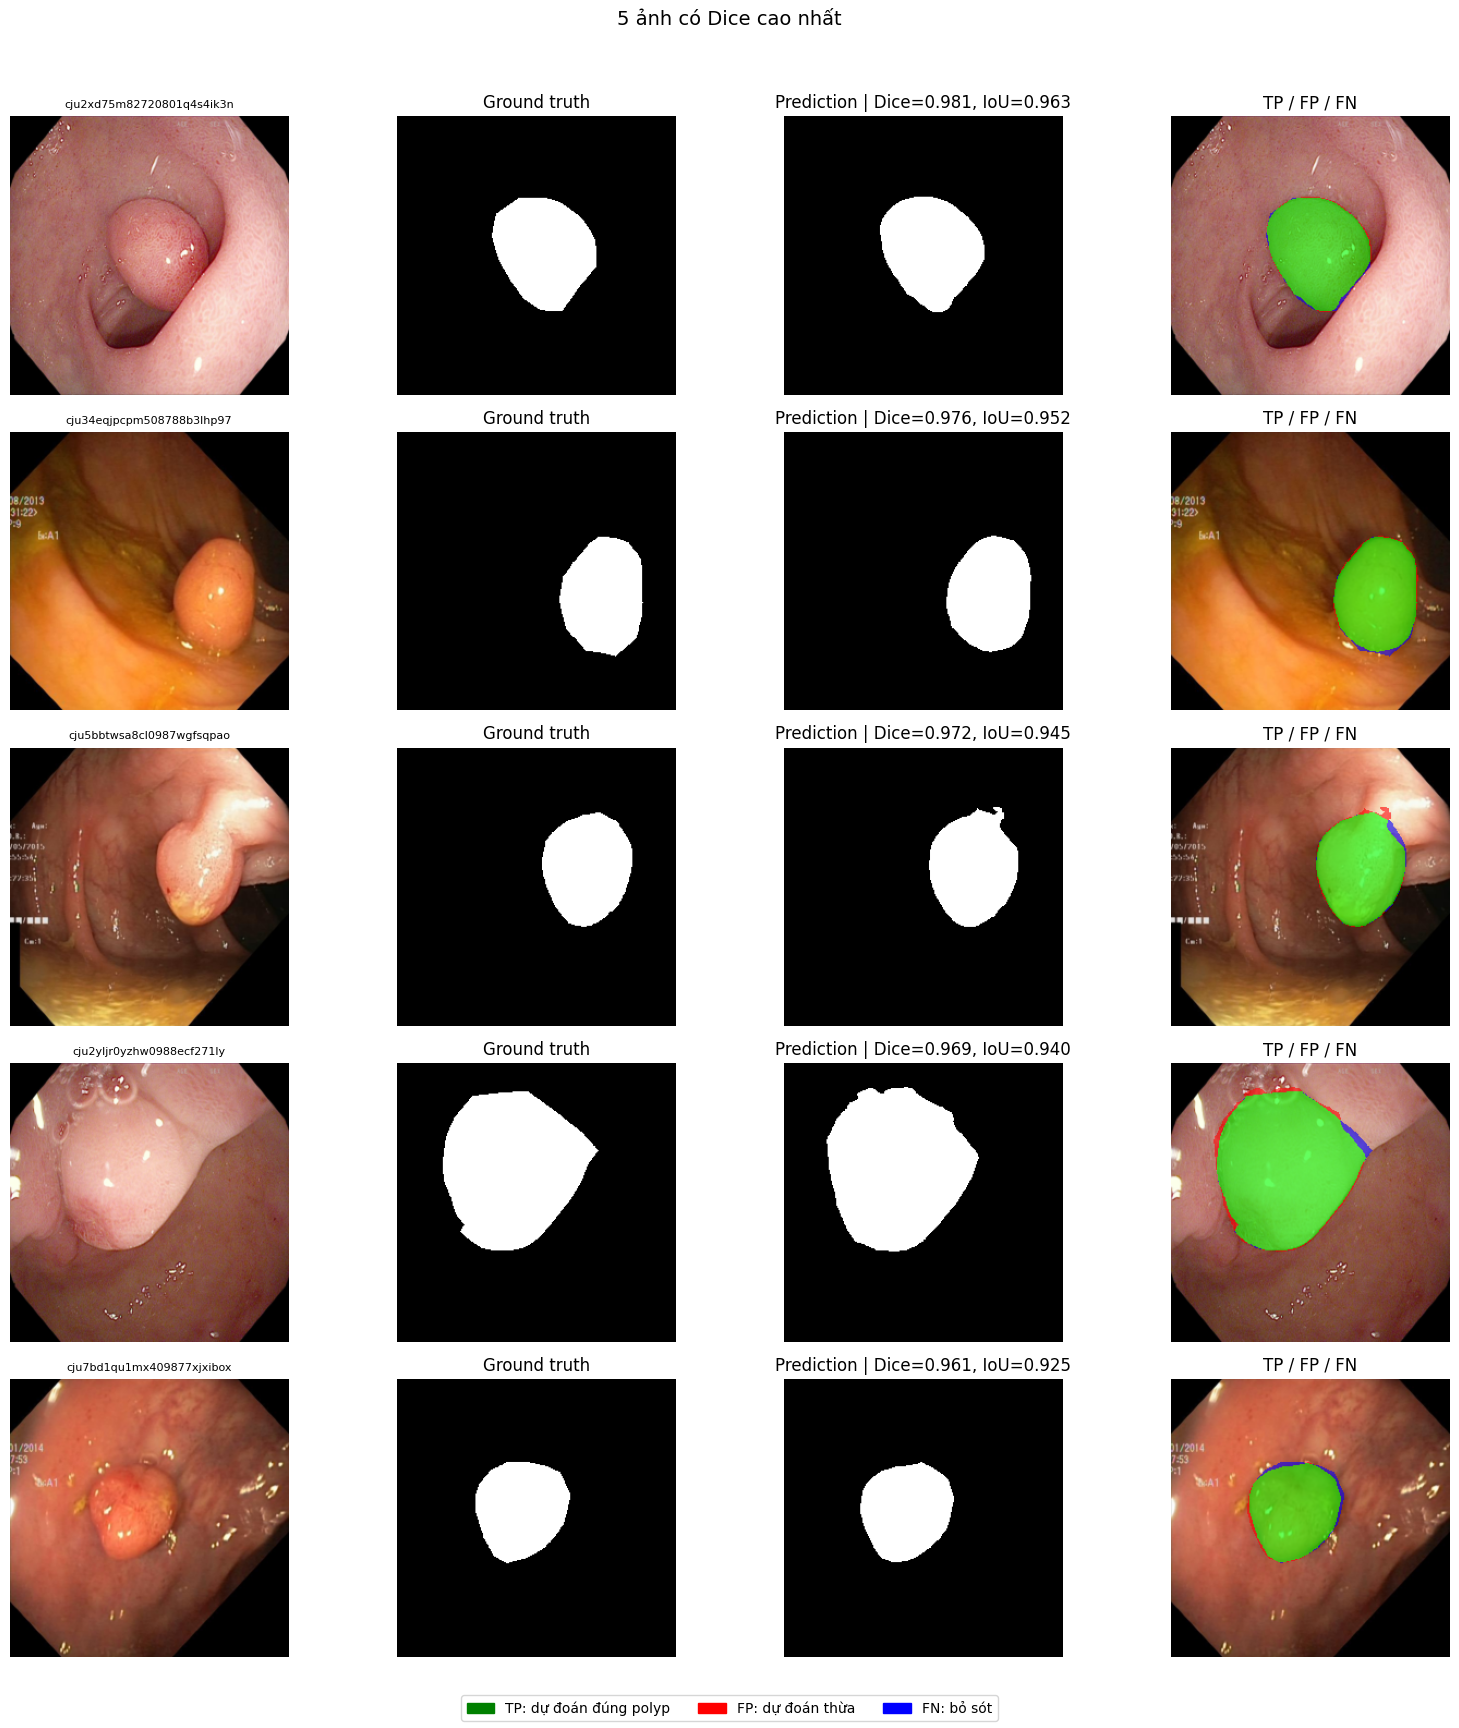

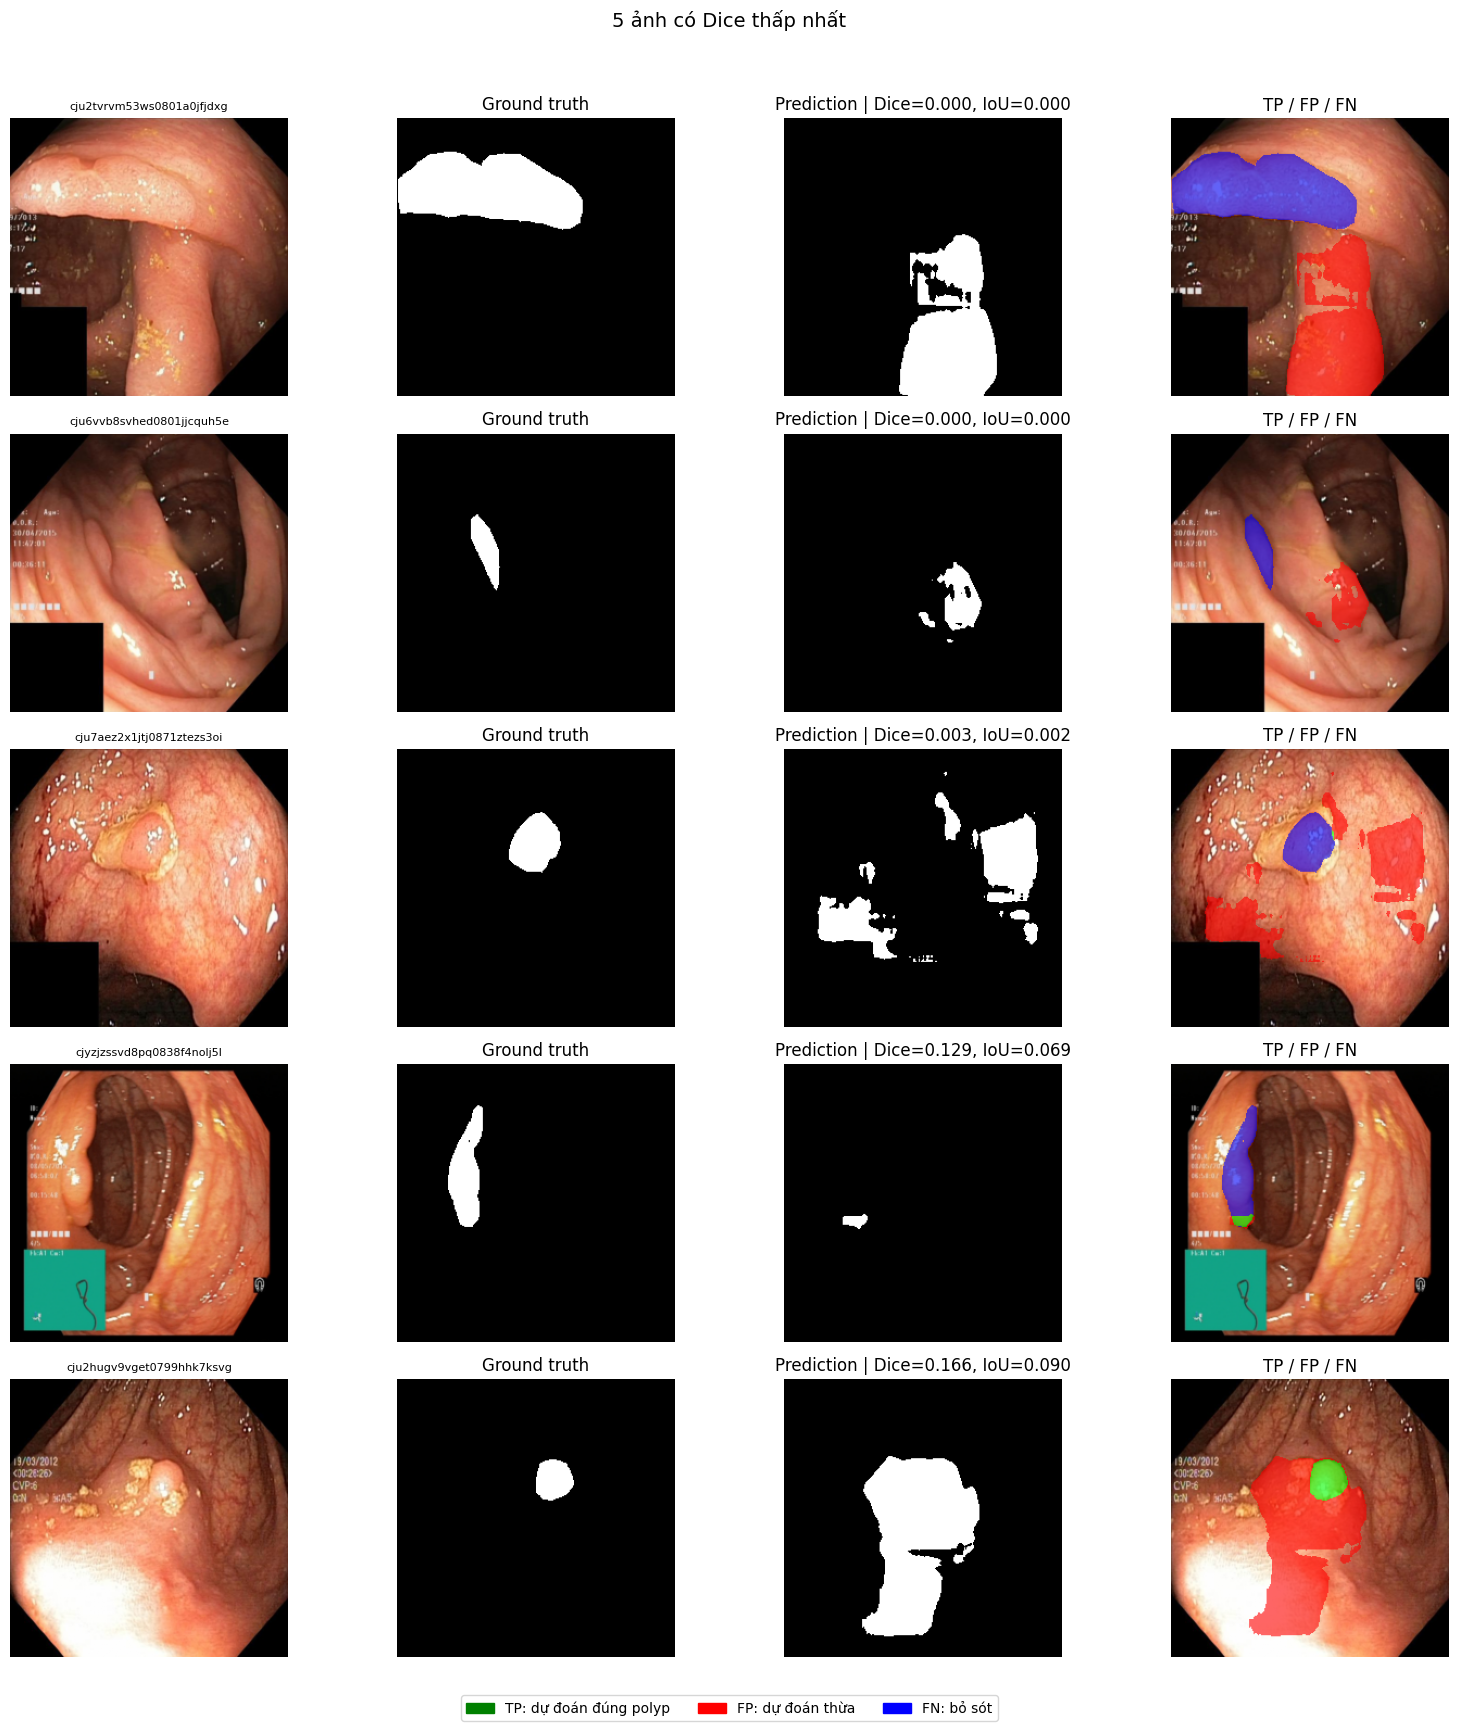

In [15]:
from matplotlib.patches import Patch

def show_analysis_cases(frame, title, filename, n=5):
    selected = frame.head(n)

    if selected.empty:
        print("Không có ảnh cho nhóm:", title)
        return

    fig, axes = plt.subplots(
        len(selected),
        4,
        figsize=(16, 3.5 * len(selected)),
        squeeze=False,
    )

    for row_axes, (_, row) in zip(axes, selected.iterrows()):
        item = analysis_cache[row["name"]]

        image = np.clip(item["image"], 0, 1)
        gt = item["gt"]
        pred = item["pred"]

        overlay = image.copy()

        for region, color in [
            (pred & gt, [0, 1, 0]),
            (pred & ~gt, [1, 0, 0]),
            (~pred & gt, [0, 0, 1]),
        ]:
            overlay[region] = (
                0.4 * image[region]
                + 0.6 * np.array(color)
            )

        row_axes[0].imshow(image)
        row_axes[0].set_title(row["name"], fontsize=8)

        row_axes[1].imshow(
            gt, cmap="gray", vmin=0, vmax=1
        )
        row_axes[1].set_title("Ground truth")

        row_axes[2].imshow(
            pred, cmap="gray", vmin=0, vmax=1
        )
        row_axes[2].set_title(
            f"Prediction | Dice={row['dice']:.3f}, "
            f"IoU={row['iou']:.3f}"
        )

        row_axes[3].imshow(overlay)
        row_axes[3].set_title("TP / FP / FN")

        for ax in row_axes:
            ax.axis("off")

    fig.suptitle(title, fontsize=14)

    fig.legend(
        handles=[
            Patch(color="green", label="TP: dự đoán đúng polyp"),
            Patch(color="red", label="FP: dự đoán thừa"),
            Patch(color="blue", label="FN: bỏ sót"),
        ],
        loc="lower center",
        ncol=3,
    )

    fig.tight_layout(rect=[0, 0.03, 1, 0.96])
    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()


show_analysis_cases(
    analysis_df.sort_values(
        ["dice", "name"], ascending=[False, True]
    ),
    "5 ảnh có Dice cao nhất",
    "test_best_cases.png",
)

show_analysis_cases(
    analysis_df.sort_values(
        ["dice", "name"], ascending=[True, True]
    ),
    "5 ảnh có Dice thấp nhất",
    "test_worst_cases.png",
)